# 04.1 Multi-Pred Causality

This notebook runs three causality protocols for the multi-predicate setup:

- **4.3a — Nudge Predicate Ordering**: Steer with the P+ direction at the pivot point and check whether the model shifts toward implementing P+ first.
- **4.3b — Adversarial Prefill Persistence**: Load pre-computed results from `scripts/causality/adversarial_persistence.py` and visualise whether P+ directions improve pass rates on adversarial prefills.
- **4.3c — Induce Predicate in Arbitrary Context** *(skeleton)*: The strongest test — steer with P+ direction in a context with no mention of the target predicate.

Prerequisites:
- MCTS has been run and contrastive directions saved by `scripts/multipred_probe.py`.
- For 4.3b: `python -m scripts.causality.adversarial_persistence` has been run first.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import json
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,5,6,7"
##################################################################

import logging
from src.utils import logging_utils
from src.utils import env_utils, experiment_utils
import torch
import transformers
from rich.console import Console
from rich.theme import Theme
import nnsight

experiment_utils.set_seed(42)

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, width=300)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")
logger.info(f"{nnsight.__version__}")

sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), "src") if "notebooks" in os.getcwd() else ".")
os.chdir(os.path.dirname(os.getcwd()) if "notebooks" in os.getcwd() else os.getcwd())

rich_print(f"Working directory: {os.getcwd()}")

2026-03-05 13:01:30 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-03-05 13:01:30 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=8, torch.cuda.get_device_name()='NVIDIA A100 80GB PCIe'
2026-03-05 13:01:30 __main__ INFO     transformers.__version__='5.3.0'
2026-03-05 13:01:30 __main__ INFO     0.6.1


Working directory: /disk/u/arnab/Codes/Projects/goals

In [3]:
from src.models import ModelandTokenizer
from src.goals.data import IncompleteCodeDataset
from src.goals.predicate_data import MultiPredicateDataset, TargetPredicate
from src.utils import env_utils

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
rich_print(f"Model loaded: {mt.name}, n_layer={mt.n_layer}, n_embd={mt.n_embd}")

2026-03-05 13:01:38 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-03-05 13:01:38 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-05 13:01:38 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f995ae9b710>
2026-03-05 13:01:38 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f995be1e350> server_hostname='huggingface.co' timeout=10
2026-03-05 13:01:38 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f995afdbb30>
2026-03-05 13:01:38 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-05 13:01:38 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-05 13:01:38 http

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-03-05 13:02:00 httpcore.connection DEBUG    close.started
2026-03-05 13:02:00 httpcore.connection DEBUG    close.complete
2026-03-05 13:02:00 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-05 13:02:00 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f993028c680>
2026-03-05 13:02:00 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f995be1e350> server_hostname='huggingface.co' timeout=10
2026-03-05 13:02:00 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f995bbede80>
2026-03-05 13:02:00 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-05 13:02:00 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-05 13:02:00 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

Model loaded: Qwen/Qwen2.5-Coder-32B-Instruct, n_layer=64, n_embd=5120

In [4]:
# Load datasets
multi_dataset = MultiPredicateDataset.load_dataset()
single_pred_dataset = IncompleteCodeDataset.load_dataset()

print(f"MultiPredicateDataset: {len(multi_dataset)} predicates")
print(f"IncompleteCodeDataset: {len(single_pred_dataset)} samples")
print(f"Available predicates: {[tp.name for tp in multi_dataset.groups]}")

2026-03-05 13:02:04 src.goals.predicate_data INFO     Loaded TargetPredicate 'has_unique_elements' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/has_unique_elements.json
2026-03-05 13:02:04 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_anagram' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_anagram.json
2026-03-05 13:02:04 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_palindrome' with 5 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_palindrome.json
2026-03-05 13:02:04 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_perfect_square' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_perfect_square.json
2026-03-05 13:02:04 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_power_of_two' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_power_of_two.json
2026-03-05 13:02:04 src.goals.pr

2026-03-05 13:02:04 src.goals.data INFO     Loaded 17 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json
MultiPredicateDataset: 6 predicates
IncompleteCodeDataset: 17 samples
Available predicates: ['has_unique_elements', 'is_anagram', 'is_palindrome', 'is_perfect_square', 'is_power_of_two', 'is_sorted']


In [5]:
# ── Pick target predicate + sample ───────────────────────────────────────────
PRED_NAME = multi_dataset.groups[2].name  # Change to pick a different predicate
SAMPLE_IDX = 4

target_predicate: TargetPredicate = next(tp for tp in multi_dataset.groups if tp.name == PRED_NAME)
sample = target_predicate.samples[SAMPLE_IDX]

print(f"Target predicate: {target_predicate.name!r}")
print(f"  P+: {target_predicate.p_plus.description}")
print(f"  P+ anchor tokens: {target_predicate.p_plus.anchor_tokens}")
if sample.p_minus:
    print(f"  P- (sample {SAMPLE_IDX}): {sample.p_minus.description}")
    print(f"  P- anchor tokens: {sample.p_minus.anchor_tokens}")
print(f"\nCode stub:\n{sample.code}")

Target predicate: 'is_palindrome'
  P+: check whether s is a palindrome (s == s[::-1])
  P+ anchor tokens: ['::-1]', '== s.lower()[::-1]', '== s[', '== s[::-1]', '==s', '>> 1]', '[::-1]', '[::-2]', 'enumerate(s)', 'lower()[::-1]', 'reversed', 's != s', 's != s[', 's != s[::-1]', 's ==', 's == s', 's == s[', 's == s[::-1]', 's.lower() ==', 's.lower()[::-1]', 's[-(', 's[-1:-3:-1]', 's[-2:]', 's[-i-1]', 's[::-', 's[::- 1]', 's[::-1]']
  P- (sample 4): check whether s == s.lower() (all lowercase)
  P- anchor tokens: ['.upper()', "<= 'Z'", '== s and', '[:1].upper()', 'islower', 'isupper', 'isupper()', 'lower()']

Code stub:
def is_lowercase_palindrome(s: str) -> bool:
    """Return True iff s consists entirely of lowercase characters and is a palindrome."""
    return 


## 4.3a — Nudge Predicate Ordering

**Protocol**: Steer generation with the P+ direction at the pivot point (right after `return`). Measure whether the steered model shifts toward implementing P+ first, even when given a P--aligned prefill.

**Metric**: Anchor-token scoring — `predicate_order()` checks whether P+ or P- anchor tokens appear first in the generated code. All orderings are correct, so unit-test pass rate is not the metric here.

**Setup**:
- Baseline: natural generation (no steering), with a P--aligned prefill to stress-test
- Steered: same prompt + P+ direction added to hidden states at last position
- Coeff sweep over a small grid × 2-3 layer windows

In [56]:
# ── 4.3a config ──────────────────────────────────────────────────────────────
PRED_NAME   = target_predicate.name   # re-declare here for easy override

model_short_name = mt.name.split("/")[-1]
SAVE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe",
    model_short_name,
    PRED_NAME,
)
rich_print(f"Loading directions from: {SAVE_DIR}")

Loading directions from: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe/Qwen2.5-Coder-32B-Instruct/is_palindrome

In [57]:
# ── Load contrastive + mean-diff directions ───────────────────────────────────
contrastive_directions = torch.load(
    os.path.join(SAVE_DIR, "contrastive_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
mean_diff_directions = torch.load(
    os.path.join(SAVE_DIR, "mean_diff_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
rich_print(f"Contrastive directions loaded: {len(contrastive_directions)} layers")
rich_print(f"Mean-diff directions loaded:   {len(mean_diff_directions)} layers")

Contrastive directions loaded: 64 layers

Mean-diff directions loaded:   64 layers

In [216]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.functional import generate_with_patch, get_hs, PatchSpec
from src.tokens import prepare_input

# ── Build prompt ─────────────────────────────────────────────────────────────
PREFILL_4A = ""

if supports_chat_template(mt):
    prompt_4a = apply_chat_template(
        mt=mt,
        user_query=sample.instruction.strip(),
        incomplete_code=sample.code + PREFILL_4A,
    )
else:
    prompt_4a = sample.instruction + "<code>" + sample.code + PREFILL_4A

print(f'"{prompt_4a}"')

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python function that returns True iff the string is all lowercase and is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_lowercase_palindrome(s: str) -> bool:
    """Return True iff s consists entirely of lowercase characters and is a palindrome."""
    return "


In [217]:
# ── Extract hidden states (all layers, last position) ─────────────────────────
tokenized = prepare_input(prompts=prompt_4a, tokenizer=mt)
locations_4a = [(mt.layer_name_format.format(l), -1) for l in range(mt.n_layer)]
hs_4a = get_hs(mt=mt, input=tokenized, locations=locations_4a)
rich_print(f"Hidden states extracted: {len(hs_4a)} locations")

Hidden states extracted: 64 locations

In [218]:
from scripts.causality.adversarial_persistence import build_steer_patches, generate_and_evaluate

# ── Baseline generation ───────────────────────────────────────────────────────
N_GENERATIONS_4A = 150

baseline_eval_4a = generate_and_evaluate(
    mt=mt,
    sample=sample,
    prefill=PREFILL_4A,
    prompt=prompt_4a,
    n_generations=N_GENERATIONS_4A,
    patches=None,
    label="baseline",
)
baseline_outputs_4a = [gen.lm_generation for gen in baseline_eval_4a.generations]
rich_print(f"Baseline generation done: {len(baseline_outputs_4a)} samples")

2026-03-05 18:16:26 scripts.causality.adversarial_persistence DEBUG    Generating 150 samples (baseline)...


2026-03-05 18:16:42 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 150 outputs...
2026-03-05 18:16:42 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 150/150 passed (1.000)


Baseline generation done: 150 samples

In [219]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(baseline_eval_4a)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:10]
pretty_print_eval_results(eval_results_filtered)

"""def is_lowercase_palindrome(s: str) -> bool:
    """Return True iff s consists entirely of lowercase characters and is a palindrome."""
    return """

                               Code Completion Results                               
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill           ┃ Logic                           ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
└───────────────────┴─────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 150/150 passed, 0/150 failed

In [220]:
# ── predicate_order helper (verbatim from cell 40 of 03.1_multi_probe.ipynb) ──
from src.goals.anchor import _extract_boolean_expr, _split_clauses
from collections import Counter

p_plus_anchors  = target_predicate.p_plus.anchor_tokens
p_minus_anchors = sample.p_minus.anchor_tokens if sample.p_minus else []


def predicate_order(text: str) -> str:
    """Return 'p_plus_first', 'p_minus_first', or 'unclear'."""
    full = sample.code + PREFILL_4A + text
    result = _extract_boolean_expr(full)
    if result is None:
        p_plus_pos  = min((full.find(a) for a in p_plus_anchors  if full.find(a) >= 0), default=None)
        p_minus_pos = min((full.find(a) for a in p_minus_anchors if full.find(a) >= 0), default=None)
    else:
        expr, _ = result
        p_plus_pos  = next((expr.find(a) for a in p_plus_anchors  if expr.find(a) >= 0), None)
        p_minus_pos = next((expr.find(a) for a in p_minus_anchors if expr.find(a) >= 0), None)

    if p_plus_pos is None and p_minus_pos is None:
        return "unclear"
    if p_minus_pos is None:
        return "p_plus_first"
    if p_plus_pos is None:
        return "p_minus_first"
    return "p_plus_first" if p_plus_pos <= p_minus_pos else "p_minus_first"


def _rate(counter, key):
    total = sum(counter.values())
    return counter.get(key, 0) / total if total > 0 else 0.0


# Baseline order counts
baseline_orders_4a = Counter(predicate_order(g) for g in baseline_outputs_4a)

rich_print(f"P+ anchors : {p_plus_anchors}")
rich_print(f"P- anchors : {p_minus_anchors}")
rich_print(f"\nBaseline predicate order: {dict(baseline_orders_4a)}")
rich_print(f"  P+ first rate: {_rate(baseline_orders_4a, 'p_plus_first'):.2f}")

P+ anchors : ['::-1]', '== s.lower()[::-1]', '== s[', '== s[::-1]', '==s', '>> 1]', '[::-1]', '[::-2]', 'enumerate(s)', 'lower()[::-1]', 'reversed', 's != s', 's != s[', 's != s[::-1]', 's ==', 's == s', 's == s[', 's == s[::-1]', 's.lower() ==', 's.lower()[::-1]', 's[-(', 's[-1:-3:-1]', 's[-2:]', 
's[-i-1]', 's[::-', 's[::- 1]', 's[::-1]']

P- anchors : ['.upper()', "<= 'Z'", '== s and', '[:1].upper()', 'islower', 'isupper', 'isupper()', 'lower()']

Baseline predicate order: {'p_minus_first': 150}

P+ first rate: 0.00

In [40]:
# ── Coeff sweep ───────────────────────────────────────────────────────────────
# Small grid; run one coeff at a time (comment in the loop for full sweep)
COEFF_GRID_4A = [-0.08, -0.04, 0.04, 0.08, 0.12, 0.2]
LAYER_RANGES_4A = [(30, 40), (40, 50)]  # (layer_from, layer_to)

# Results dict: results_4a[direction_type][layer_tag][coeff] = p_plus_first_rate
results_4a = {"contrastive": {}, "mean_diff": {}}

for layer_from, layer_to in LAYER_RANGES_4A:
    layer_tag = f"{layer_from}-{layer_to}"
    results_4a["contrastive"][layer_tag] = {}
    results_4a["mean_diff"][layer_tag] = {}

    for coeff in COEFF_GRID_4A:
        for dir_type, directions in [
            ("contrastive", contrastive_directions),
            ("mean_diff", mean_diff_directions),
        ]:
            patches = build_steer_patches(
                mt=mt,
                directions=directions,
                hs=hs_4a,
                layer_from=layer_from,
                layer_to=layer_to,
                coeff=coeff,
            )
            steered_eval = generate_and_evaluate(
                mt=mt,
                sample=sample,
                prefill=PREFILL_4A,
                prompt=prompt_4a,
                n_generations=N_GENERATIONS_4A,
                patches=patches if coeff != 0.0 else None,
                label=f"{dir_type} layers={layer_tag} coeff={coeff:.2f}",
            )
            steered_outputs = [gen.lm_generation for gen in steered_eval.generations]
            orders = Counter(predicate_order(g) for g in steered_outputs)
            rate = _rate(orders, "p_plus_first")
            results_4a[dir_type][layer_tag][coeff] = rate
            rich_print(
                f"  [white][bold]{dir_type}[/bold][/white]: layers={layer_tag} coeff={coeff:+.2f} → P+ first={rate:.2f}"
            )

rich_print("\nCoeff sweep complete.")

2026-03-04 14:51:20 scripts.causality.adversarial_persistence DEBUG    Generating 150 samples (contrastive layers=30-40 coeff=-0.08)...
2026-03-04 14:51:34 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 150 outputs...
2026-03-04 14:51:34 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 150/150 passed (1.000)


contrastive: layers=30-40 coeff=-0.08 → P+ first=0.00

2026-03-04 14:51:34 scripts.causality.adversarial_persistence DEBUG    Generating 150 samples (mean_diff layers=30-40 coeff=-0.08)...
2026-03-04 14:51:50 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 150 outputs...
2026-03-04 14:51:50 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 41/150 passed (0.273)


mean_diff: layers=30-40 coeff=-0.08 → P+ first=0.00

2026-03-04 14:51:50 scripts.causality.adversarial_persistence DEBUG    Generating 150 samples (contrastive layers=30-40 coeff=-0.04)...
2026-03-04 14:52:07 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 150 outputs...
2026-03-04 14:52:07 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 150/150 passed (1.000)


contrastive: layers=30-40 coeff=-0.04 → P+ first=0.00

... (39 outputs left out)

contrastive: layers=40-50 coeff=+0.20 → P+ first=0.20

2026-03-04 14:56:50 scripts.causality.adversarial_persistence DEBUG    Generating 150 samples (mean_diff layers=40-50 coeff=0.20)...
2026-03-04 14:57:07 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 150 outputs...
2026-03-04 14:57:07 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 0/150 passed (0.000)


mean_diff: layers=40-50 coeff=+0.20 → P+ first=1.00

Coeff sweep complete.

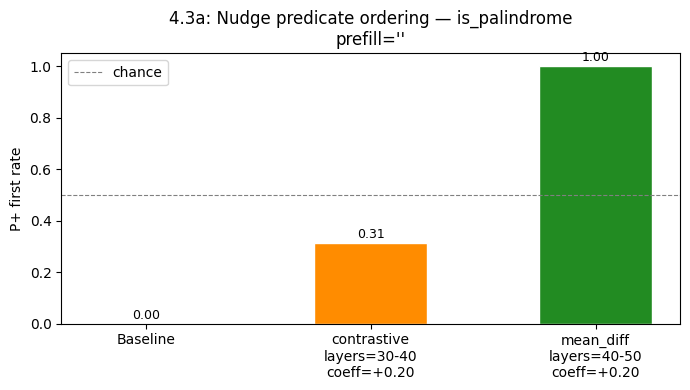

In [41]:
from matplotlib import pyplot as plt

# ── Visualise: bar chart (baseline vs best steered) ───────────────────────────
baseline_rate_4a = _rate(baseline_orders_4a, "p_plus_first")

# Find best steered rate across all configs for each direction type
best_steered = {}
for dir_type in ("contrastive", "mean_diff"):
    all_rates = [
        (rate, layer_tag, coeff)
        for layer_tag, coeff_dict in results_4a[dir_type].items()
        for coeff, rate in coeff_dict.items()
        if coeff > 0  # positive = toward P+
    ]
    if all_rates:
        best_rate, best_layer, best_coeff = max(all_rates, key=lambda x: x[0])
        best_steered[dir_type] = (best_rate, best_layer, best_coeff)

labels = ["Baseline"] + [
    f"{dt}\nlayers={v[1]}\ncoeff={v[2]:+.2f}"
    for dt, v in best_steered.items()
]
values = [baseline_rate_4a] + [v[0] for v in best_steered.values()]
colors = ["steelblue"] + ["darkorange", "forestgreen"][:len(best_steered)]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, values, color=colors, edgecolor="white", width=0.5)
ax.set_ylim(0, 1.05)
ax.set_ylabel("P+ first rate")
ax.set_title(f"4.3a: Nudge predicate ordering — {PRED_NAME}\nprefill={PREFILL_4A!r}")
ax.axhline(0.5, color="gray", linewidth=0.8, linestyle="--", label="chance")
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.02, f"{val:.2f}", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.show()

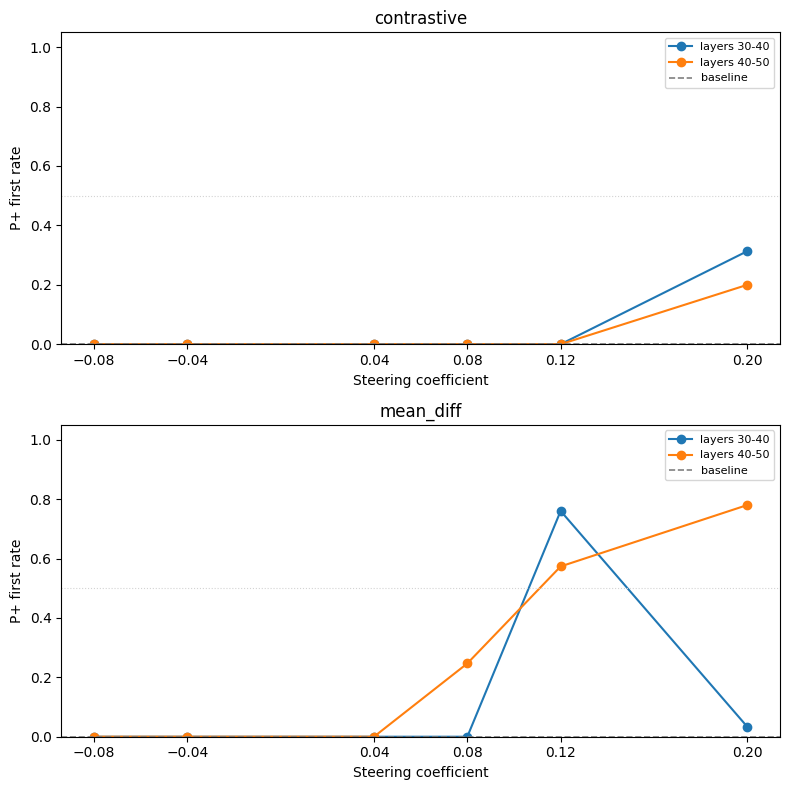

In [73]:
# ── Visualise: line plot of P+ first rate vs coeff per layer window ────────────
fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharey=True)

for ax, dir_type in zip(axes, ["contrastive", "mean_diff"]):
    for layer_tag, coeff_dict in results_4a[dir_type].items():
        coeffs = sorted(coeff_dict.keys())
        rates  = [coeff_dict[c] for c in coeffs]
        ax.plot(coeffs, rates, marker="o", label=f"layers {layer_tag}")
    ax.axhline(baseline_rate_4a, color="gray", linewidth=1.2, linestyle="--", label="baseline")
    ax.axhline(0.5, color="lightgray", linewidth=0.8, linestyle=":")
    ax.set_xlabel("Steering coefficient")
    ax.set_ylabel("P+ first rate")
    ax.set_title(f"{dir_type}")
    ax.legend(fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(coeffs)

# fig.suptitle(f"4.3a: P+ first rate vs coeff — {PRED_NAME}  (prefill={PREFILL_4A!r})", y=1.00)
plt.tight_layout()
plt.show()

In [221]:
SAVE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe",
    model_short_name,
    PRED_NAME,
    # "is_sorted"
)
rich_print(f"Loading directions from: {SAVE_DIR}")

# ── Load contrastive + mean-diff directions ───────────────────────────────────
contrastive_directions = torch.load(
    os.path.join(SAVE_DIR, "contrastive_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
mean_diff_directions = torch.load(
    os.path.join(SAVE_DIR, "mean_diff_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
rich_print(f"Contrastive directions loaded: {len(contrastive_directions)} layers")
rich_print(f"Mean-diff directions loaded:   {len(mean_diff_directions)} layers")

Loading directions from: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe/Qwen2.5-Coder-32B-Instruct/is_palindrome

Contrastive directions loaded: 64 layers

Mean-diff directions loaded:   64 layers

In [222]:
from src.tokens import prepare_input
from src.functional import PatchSpec, _generate_baukit
from collections import Counter

################################
DIR_TYPE = "contrastive"  # or "mean_diff"
LAYER_FROM = 30
LAYER_TO = 40
COEFF = 0.20
################################

directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

patches = build_steer_patches(
    mt=mt,
    directions=directions,
    hs=hs_4a,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
)

prompt_tokenized = prepare_input(prompts=prompt_4a, tokenizer=mt)
n_tokens = prompt_tokenized.input_ids.shape[1]

context_patches = []
for li in range(LAYER_FROM, LAYER_TO):
    layer_name = mt.layer_name_format.format(li)
    h_orig = hs_4a[(layer_name, -1)]
    goal_dir = directions[li].to(h_orig.dtype).to(h_orig.device)
    scaled_goal_dir = goal_dir * COEFF * (h_orig.norm() / goal_dir.norm())
    context_patches.extend(
        [
            PatchSpec(
                location=(layer_name, token_idx),
                patch=scaled_goal_dir,
                strategy="add",
                on_pass="first",
            )
            for token_idx in range(0, n_tokens - 1)
            # for token_idx in range(-25, -1)
        ]
    )


steered_eval_results = generate_and_evaluate(
    mt=mt,
    sample=sample,
    prefill=PREFILL_4A,
    prompt=prompt_4a,
    n_generations=N_GENERATIONS_4A,
    # patches=patches + context_patches,
    patches=patches,
    label="steering",
    patch_interface="baukit",
)


steered_outputs = [gen.lm_generation for gen in steered_eval_results.generations]
orders = Counter(predicate_order(g) for g in steered_outputs)
rate = _rate(orders, "p_plus_first")

rich_print(
    f"  [white][bold]{DIR_TYPE}[/bold][/white]: layers={LAYER_FROM}-{LAYER_TO} coeff={COEFF:+.2f} → P+ first={rate:.2f}"
)

2026-03-05 18:18:05 scripts.causality.adversarial_persistence DEBUG    Generating 150 samples (steering)...


2026-03-05 18:18:23 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 150 outputs...
2026-03-05 18:18:23 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 81/150 passed (0.540)


contrastive: layers=30-40 coeff=+0.20 → P+ first=0.27

In [66]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(steered_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    if gen.eval.verdict == "PASSED" and predicate_order(gen.lm_generation) == "p_plus_first"
][:10]
pretty_print_eval_results(eval_results_filtered)

"""def is_lowercase_palindrome(s: str) -> bool:
    """Return True iff s consists entirely of lowercase characters and is a palindrome."""
    return """

                               Code Completion Results                               
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill           ┃ Logic                           ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
└───────────────────┴─────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 144/150 passed, 6/150 failed

## 4.3b — Adversarial Prefill Persistence

**Protocol**: Take a standard single-predicate task (e.g., `is_palindrome`) where adversarial prefills (e.g., `1 +`, `(3`) confuse the model into failing. Steer with the goal direction trained from the multi-pred setup. Does the direction "remind" the model what it is supposed to do, improving pass rate?

In [103]:
from scripts.causality.results import AdversarialPersistenceResults

model_short_name = mt.name.split("/")[-1]
# ── 4.3b config ──────────────────────────────────────────────────────────────
PRED_NAME_4B   = PRED_NAME          # can override to pick a different predicate
RESULTS_DIR_4B = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, "multi_causality", model_short_name, PRED_NAME_4B
)
summary_path = os.path.join(RESULTS_DIR_4B, "summary.json")

rich_print(f"Loading results from: {summary_path}")
r = AdversarialPersistenceResults.load(summary_path)

rich_print(f"Predicate: {r.data['predicate_name']}")
rich_print(f"P+: {r.data['p_plus_description']}")
rich_print(f"N generations: {r.data['n_generations']}")
rich_print(f"Prefills in results: {list(r.data['prefill_results'].keys())}")

Loading results from: /disk/u/arnab/Codes/Projects/goals/results/multi_causality/Qwen2.5-Coder-32B-Instruct/is_palindrome/summary.json

Predicate: is_palindrome

P+: check whether s is a palindrome (s == s[::-1])

N generations: 200

Prefills in results: ['(3', '1 -', '1 +', 'not', 'not not', '5', '3 +', '0', '0 +']

In [104]:
from rich.table import Table

# ── Summary table: per-prefill baseline / best contrastive Δ / best mean_diff Δ ──
table = Table(title=f"4.3b Summary — {PRED_NAME_4B}", show_lines=True)
table.add_column("Prefill", style="bright_yellow", no_wrap=True)
table.add_column("Baseline", style="white", justify="right")
table.add_column("Contrastive", style="orange1", justify="right")
table.add_column("Δc (α, layer)", style="white", justify="right")
table.add_column("MeanDiff", style="bright_green", justify="right")
table.add_column("Δm (α, layer)", style="white", justify="right")

for pfx, pfr in r.data["prefill_results"].items():
    baseline = pfr["baseline_pass_rate"]
    bc = pfr.get("best_contrastive")
    bm = pfr.get("best_mean_diff")

    c_rate_str = f"{bc['pass_rate']:.3f}" if bc else "—"
    delta_c_str = f"{bc['pass_rate'] - baseline:+.3f}" if bc else "—"
    delta_c_str += f" ({float(bc['coeff']):.2f}, {bc['layer_idx']})" if bc else ""
    m_rate_str = f"{bm['pass_rate']:.3f}" if bm else "—"
    delta_m_str = f"{bm['pass_rate'] - baseline:+.3f}" if bm else "—"
    delta_m_str += f" ({float(bm['coeff']):.2f}, {bm['layer_idx']})" if bm else ""

    table.add_row(
        repr(pfx),
        f"{baseline:.3f}",
        c_rate_str,
        delta_c_str,
        m_rate_str,
        delta_m_str,
    )

console.print(table)

                              4.3b Summary — is_palindrome                               
┏━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Prefill   ┃ Baseline ┃ Contrastive ┃     Δc (α, layer) ┃ MeanDiff ┃     Δm (α, layer) ┃
┡━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ '(3'      │    0.450 │       0.730 │ +0.280 (0.06, 30) │    0.660 │ +0.210 (0.04, 35) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '1 -'     │    0.000 │       0.180 │ +0.180 (0.08, 25) │    0.380 │ +0.380 (0.12, 30) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '1 +'     │    0.350 │       0.435 │ +0.085 (0.10, 50) │    0.325 │ -0.025 (0.02, 50) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ 'not'     │    1.000 │       1.000 │ +0.000 (0.02, 25) │    1.000 │ +0.000 (0.02, 25) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ 'not not' │    0.000 │       1.000 │ +1.000 (0.12, 25) │    0.725 │ +0.725 (0.08, 40) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '5'       │    0.000 │       0.420 │ +0.420 (0.16, 50) │    0.005 │ +0.005 (0.16, 30) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '3 +'     │    0.000 │       0.040 │ +0.040 (0.04, 40) │    0.010 │ +0.010 (0.14, 30) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '0'       │    0.795 │       1.000 │ +0.205 (0.02, 50) │    1.000 │ +0.205 (0.04, 50) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '0 +'     │    0.410 │       0.605 │ +0.195 (0.04, 45) │    0.850 │ +0.440 (0.04, 50) │
└───────────┴──────────┴─────────────┴───────────────────┴──────────┴───────────────────┘

2026-03-05 16:02:52 matplotlib.colorbar DEBUG    locator: <matplotlib.ticker.AutoLocator object at 0x7f986ca667e0>


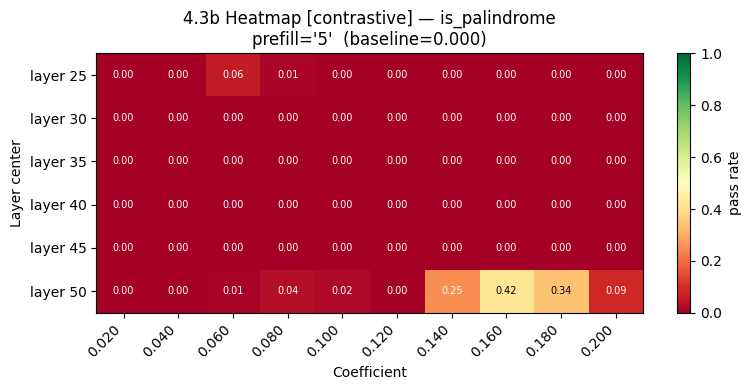

In [105]:
import numpy as np
from matplotlib import pyplot as plt

# ── Heatmap: pass_rate[layer][coeff] for contrastive, for a chosen prefill ───
HEATMAP_PREFILL = list(r.data["prefill_results"].keys())[5]  # change as needed
HEATMAP_DIR_TYPE = "contrastive"  # "contrastive" or "mean_diff"

by_layer = r.data["prefill_results"][HEATMAP_PREFILL]["by_layer"]
baseline_rate_hm = r.data["prefill_results"][HEATMAP_PREFILL]["baseline_pass_rate"]

# Collect all layer_idx and coeff keys
layer_keys = sorted(by_layer.keys(), key=int)
by_coeff_key = f"{HEATMAP_DIR_TYPE}_by_coeff"
all_coeffs = sorted(
    {c for ld in by_layer.values() for c in ld.get(by_coeff_key, {})},
    key=float,
)

# Build 2D array: rows = layers, cols = coeffs
matrix = np.full((len(layer_keys), len(all_coeffs)), np.nan)
for row_i, lk in enumerate(layer_keys):
    for col_j, ck in enumerate(all_coeffs):
        val = by_layer[lk].get(by_coeff_key, {}).get(ck)
        if val is not None:
            matrix[row_i, col_j] = val

fig, ax = plt.subplots(figsize=(max(8, len(all_coeffs) * 0.8), max(4, len(layer_keys) * 0.5 + 1)))
im = ax.imshow(matrix, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label="pass rate")
ax.set_xticks(range(len(all_coeffs)))
ax.set_xticklabels(all_coeffs, rotation=45, ha="right")
ax.set_yticks(range(len(layer_keys)))
ax.set_yticklabels([f"layer {lk}" for lk in layer_keys])
ax.set_xlabel("Coefficient")
ax.set_ylabel("Layer center")
ax.set_title(
    f"4.3b Heatmap [{HEATMAP_DIR_TYPE}] — {PRED_NAME_4B}\n"
    f"prefill={HEATMAP_PREFILL!r}  (baseline={baseline_rate_hm:.3f})"
)
# Annotate cells
for ri in range(len(layer_keys)):
    for ci in range(len(all_coeffs)):
        val = matrix[ri, ci]
        if not np.isnan(val):
            ax.text(ci, ri, f"{val:.2f}", ha="center", va="center", fontsize=7,
                    color="black" if 0.3 < val < 0.8 else "white")
plt.tight_layout()
plt.show()

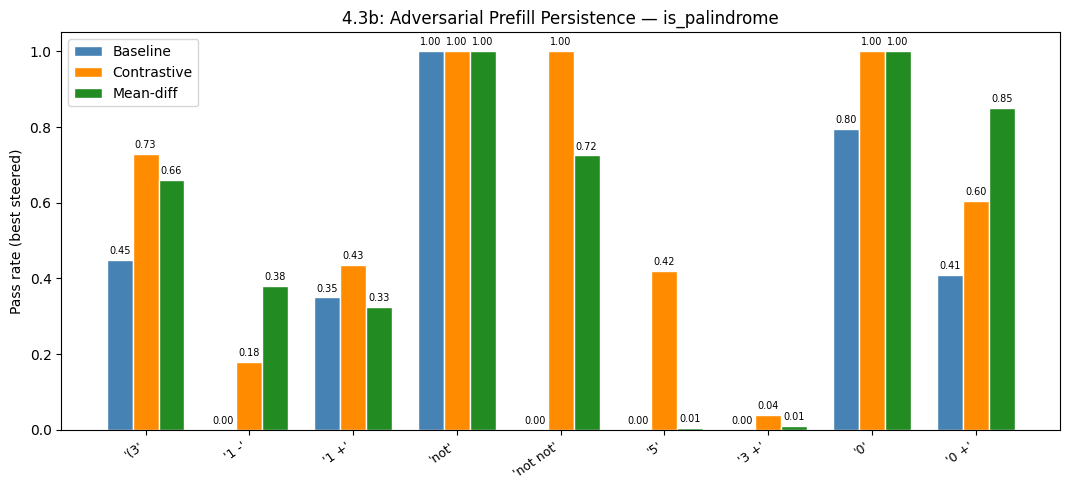

In [106]:
# ── Bar chart: for all prefills, grouped bars (baseline / contrastive / mean_diff) ──
pfx_list   = list(r.data["prefill_results"].keys())
baseline_vals     = [r.data["prefill_results"][p]["baseline_pass_rate"] for p in pfx_list]
contrastive_vals  = [
    (r.data["prefill_results"][p]["best_contrastive"] or {}).get("pass_rate", float("nan"))
    for p in pfx_list
]
mean_diff_vals    = [
    (r.data["prefill_results"][p]["best_mean_diff"] or {}).get("pass_rate", float("nan"))
    for p in pfx_list
]

x      = np.arange(len(pfx_list))
width  = 0.25
fig, ax = plt.subplots(figsize=(max(8, len(pfx_list) * 1.2), 5))

b1 = ax.bar(x - width, baseline_vals,    width, label="Baseline",    color="steelblue",   edgecolor="white")
b2 = ax.bar(x,          contrastive_vals, width, label="Contrastive", color="darkorange",  edgecolor="white")
b3 = ax.bar(x + width,  mean_diff_vals,   width, label="Mean-diff",   color="forestgreen", edgecolor="white")

ax.set_xticks(x)
ax.set_xticklabels([repr(p) for p in pfx_list], rotation=35, ha="right", fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Pass rate (best steered)")
ax.set_title(f"4.3b: Adversarial Prefill Persistence — {PRED_NAME_4B}")
ax.legend()

for bar_group in [b1, b2, b3]:
    for bar in bar_group:
        h = bar.get_height()
        if not np.isnan(h):
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:.2f}",
                    ha="center", va="bottom", fontsize=7)

plt.tight_layout()
plt.show()

In [107]:
from src.goals.functional import supports_chat_template, apply_chat_template

single_pred_sample = [
    d for d in single_pred_dataset if d.function_name == PRED_NAME
][0]
rich_print(single_pred_sample)

# Use an inconsequential (unprefilled) prompt to see the model's natural preference
prefill = "5"
if supports_chat_template(mt):
    prompt = apply_chat_template(
        mt=mt,
        user_query=single_pred_sample.instruction.strip()
        if hasattr(single_pred_sample, "instruction")
        else "",
        incomplete_code=single_pred_sample.code + prefill,
    )
else:
    prompt = single_pred_sample.code + prefill

prefill_idx = prompt.index(prefill.strip())
rich_print(
    f'"[white]{prompt[:prefill_idx]}[/white][bright_yellow]{prompt[prefill_idx:]}[/bright_yellow]"'
)

IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is a palindrome.\n\n',
    code='def is_palindrome(s: str) -> bool:\n    return True if ',
    unit_tests=[('racecar', True), ('hello', False), ('', True), ('a', True), ('ab', False), ('aba', True), ('abba', True)],
    prefills={'aligned': ['', '(', 's', 's ==', 's == s', 's[::', 's[::-1]', '(s', 'list(', 'list(s)'], 'adversarial': ['not', 'not (', 's +', '3', '1 +'], 'inconsequential': ['bool(', 'True and', 'False or', '0 +']},
    function_name='is_palindrome'
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    return True if 5"

In [108]:
SAVE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe",
    model_short_name,
    PRED_NAME,
)
rich_print(f"Loading directions from: {SAVE_DIR}")

# ── Load contrastive + mean-diff directions ───────────────────────────────────
contrastive_directions = torch.load(
    os.path.join(SAVE_DIR, "contrastive_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
mean_diff_directions = torch.load(
    os.path.join(SAVE_DIR, "mean_diff_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
rich_print(f"Contrastive directions loaded: {len(contrastive_directions)} layers")
rich_print(f"Mean-diff directions loaded:   {len(mean_diff_directions)} layers")

Loading directions from: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe/Qwen2.5-Coder-32B-Instruct/is_palindrome

Contrastive directions loaded: 64 layers

Mean-diff directions loaded:   64 layers

In [109]:
from scripts.causality.adversarial_persistence import (
    build_steer_patches,
    generate_and_evaluate,
)

baseline_eval_results = generate_and_evaluate(
    mt=mt,
    sample=single_pred_sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=200,
    patches=None,
    label="baseline",
)

2026-03-05 16:03:09 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (baseline)...


2026-03-05 16:03:28 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 200 outputs...
2026-03-05 16:03:28 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 0/200 passed (0.000)


In [122]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(baseline_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_filtered)

"""def is_palindrome(s: str) -> bool:
    return True if """

                                                 Code Completion Results                                                 
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill            ┃ Logic                           ┃ Verdict ┃ Unit Tests                                    ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "5" │ "5 == s == s[::-1] else False"  │ FAILED  │ is_palindrome(racecar)=False, expected True ✗ │      │
│                    │                                 │         │ is_palindrome(hello)=False ✓                  │      │
│                    │                                 │         │ is_palindrome()=False, expected True ✗        │      │
│                    │                                 │         │ is_palindrome(a)=False, expected True ✗       │      │
│                    │                                 │         │ is_palindrome(ab)=False ✓                     │      │
│                    │                                 │         │ is_palindrome(aba)=False, expected True ✗     │      │
│                    │                                 │         │ is_palindrome(abba)=False, expected True ✗    │      │
├────────────────────┼─────────────────────────────────┼─────────┼───────────────────────────────────────────────┼──────┤
│ steering_eval: "5" │ "5 == s == s[::-1] else False"  │ FAILED  │ is_palindrome(racecar)=False, expected True ✗ │      │
│                    │                                 │         │ is_palindrome(hello)=False ✓                  │      │
│                    │                                 │         │ is_palindrome()=False, expected True ✗        │      │
│                    │                                 │         │ is_palindrome(a)=False, expected True ✗       │      │
│                    │                                 │         │ is_palindrome(ab)=False ✓                     │      │
│                    │                                 │         │ is_palindrome(aba)=False, expected True ✗     │      │
│                    │                                 │         │ is_palindrome(abba)=False, expected True ✗    │      │
├────────────────────┼─────────────────────────────────┼─────────┼───────────────────────────────────────────────┼──────┤
│ steering_eval: "5" │ "5 == s == s[::-1] else False"  │ FAILED  │ is_palindrome(racecar)=False, expected True ✗ │      │
│                    │                                 │         │ is_palindrome(hello)=False ✓                  │      │
│                    │                                 │         │ is_palindrome()=False, expected True ✗        │      │
│                    │                                 │         │ is_palindrome(a)=False, expected True ✗       │      │
│                    │                                 │         │ is_palindrome(ab)=False ✓                     │      │
│                    │                                 │         │ is_palindrome(aba)=False, expected True ✗     │      │
│                    │                                 │         │ is_palindrome(abba)=False, expected True ✗    │      │
├────────────────────┼─────────────────────────────────┼─────────┼───────────────────────────────────────────────┼──────┤
│ steering_eval: "5" │ "5 == len(s) else s == s[::-1]" │ FAILED  │ is_palindrome(racecar)=True ✓                 │      │
│                    │                                 │         │ is_palindrome(hello)=True, expected False ✗   │      │
│                    │                                 │         │ is_palindrome()=True ✓                        │      │
│                    │                                 │         │ is_palindrome(a)=True ✓                       │      │
│                    │                                 │         │ is_palindrome(ab)=False ✓    

Summary: 0/200 passed, 200/200 failed

In [120]:
from src.tokens import prepare_input
from src.functional import PatchSpec
from collections import Counter
from src.tokens import prepare_input
from src.functional import get_hs
from scripts.causality.adversarial_persistence import (
    build_steer_patches,
    generate_and_evaluate,
    build_context_patches
)

tokenized = prepare_input(prompts=prompt, tokenizer=mt)
n_tokens = tokenized.input_ids.shape[1]
hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(mt.layer_name_format.format(li), -1) for li in range(mt.n_layer)]
    + [
        (mt.layer_name_format.format(li), tok_idx)
        for li in range(mt.n_layer)
        for tok_idx in range(n_tokens - 1)
    ],
)

################################
DIR_TYPE = "contrastive"  # or "mean_diff"
LAYER_FROM = 46
LAYER_TO = 55
COEFF = 0.10
N_GENERATIONS_4B = 200
################################

directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

patches = build_steer_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
)

prompt_tokenized = prepare_input(prompts=prompt, tokenizer=mt)
n_tokens = prompt_tokenized.input_ids.shape[1]

# context_patches = []
# for li in range(LAYER_FROM, LAYER_TO):
#     layer_name = mt.layer_name_format.format(li)
#     # h_orig = hs[(layer_name, -1)]
#     goal_dir = directions[li].to(h_orig.dtype).to(h_orig.device)
#     # scaled_goal_dir = goal_dir * COEFF * (h_orig.norm() / goal_dir.norm())
#     context_patches.extend(
#         [
#             PatchSpec(
#                 location=(layer_name, token_idx),
#                 patch=goal_dir
#                 * COEFF
#                 * (
#                     hs[(layer_name, token_idx)]
#                     .norm()
#                     .to(goal_dir.dtype)
#                     .to(goal_dir.device)
#                     / goal_dir.norm()
#                 ),
#                 strategy="add",
#                 on_pass="first",
#             )
#             for token_idx in range(0, n_tokens - 1)
#             # for token_idx in range(-25, -1)
#         ]
#     )

context_patches = build_context_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
    n_tokens=n_tokens,
)

steered_eval_results = generate_and_evaluate(
    mt=mt,
    sample=single_pred_sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=N_GENERATIONS_4B,
    patches=patches + context_patches,
    # patches=patches,
    label=DIR_TYPE,
    patch_interface="baukit",
)

2026-03-05 16:08:52 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (contrastive)...
2026-03-05 16:09:10 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 200 outputs...
2026-03-05 16:09:10 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 42/200 passed (0.210)


In [121]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(steered_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    if gen.eval.verdict == "PASSED"
][:10]
pretty_print_eval_results(eval_results_filtered)

"""def is_palindrome(s: str) -> bool:
    return True if """

                            Code Completion Results                             
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill            ┃ Logic                     ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "5" │ "5 > 6 else s == s[::-1]" │ PASSED  │            │      │
├────────────────────┼───────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "5" │ "5 > 6 else s == s[::-1]" │ PASSED  │            │      │
├────────────────────┼───────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "5" │ "5 > 6 else s == s[::-1]" │ PASSED  │            │      │
├────────────────────┼───────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "5" │ "5 > 6 else s[::-1] == s" │ PASSED  │            │      │
├────────────────────┼───────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "5" │ "5 > 6 else s[::-1] == s" │ PASSED  │            │      │
├────────────────────┼───────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "5" │ "5 > 6 else s == s[::-1]" │ PASSED  │            │      │
├────────────────────┼───────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "5" │ "5 > 6 else s == s[::-1]" │ PASSED  │            │      │
├────────────────────┼───────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "5" │ "5 > 6 else s == s[::-1]" │ PASSED  │            │      │
├────────────────────┼───────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "5" │ "5 > 6 else s == s[::-1]" │ PASSED  │            │      │
├────────────────────┼───────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "5" │ "5 > 6 else s[::-1] == s" │ PASSED  │            │      │
└────────────────────┴───────────────────────────┴─────────┴────────────┴──────┘

Summary: 42/200 passed, 158/200 failed

## 4.3c — Induce Predicate in a unrelated context

**Protocol** (strongest test): Take an (a) arbitrary code generation context that has *no mention of the target predicate in its instructions* or (b) a function with a different predicate. Steer with the P+ goal direction. Check whether the model spontaneously introduces P+-related code (e.g., inserts a palindrome check where none was requested or an unrelated predicate is_vowel was requested).

**Claim**: If the direction encodes a generalizable intent to "do P+", steering should induce the model to insert P+-related code even in an unrelated context.

**Metric**: Frequency of P+ anchor tokens in steered vs baseline outputs.

In [158]:
for d in single_pred_dataset:
    print(d.function_name)

is_odd
is_even
is_non_negative
is_negative
is_zero
is_palindrome
is_empty
is_uppercase
is_digit_string
is_vowel
is_power_of_two
is_sorted
has_duplicates
all_same
is_anagram
is_perfect_square
has_unique_elements


In [159]:
from src.goals.functional import supports_chat_template, apply_chat_template

PRED_NAME = multi_dataset.groups[2].name 
logger.info(f"Selected predicate: {PRED_NAME}")


source_sample = [
    d for d in single_pred_dataset if d.function_name == PRED_NAME
][0]
rich_print(source_sample)

prefill = ""
if supports_chat_template(mt):
    source_prompt = apply_chat_template(
        mt=mt,
        user_query=source_sample.instruction.strip()
        if hasattr(source_sample, "instruction")
        else "",
        incomplete_code=source_sample.code + prefill,
    )
else:
    source_prompt = source_sample.code + prefill

rich_print(
    f'"[white]{source_prompt}[/white]"'
)

2026-03-05 17:05:55 __main__ INFO     Selected predicate: is_palindrome


IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is a palindrome.\n\n',
    code='def is_palindrome(s: str) -> bool:\n    return True if ',
    unit_tests=[('racecar', True), ('hello', False), ('', True), ('a', True), ('ab', False), ('aba', True), ('abba', True)],
    prefills={'aligned': ['', '(', 's', 's ==', 's == s', 's[::', 's[::-1]', '(s', 'list(', 'list(s)'], 'adversarial': ['not', 'not (', 's +', '3', '1 +'], 'inconsequential': ['bool(', 'True and', 'False or', '0 +']},
    function_name='is_palindrome'
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    return True if "

In [160]:
import random

# destination_sample = random.choice([
#     d for d in single_pred_dataset if d.function_name != PRED_NAME
# ])
DEST_PRED_NAME = "is_uppercase"
destination_sample = [
    d for d in single_pred_dataset if d.function_name == DEST_PRED_NAME
][0]

rich_print(destination_sample)

if supports_chat_template(mt):
    destination_prompt = apply_chat_template(
        mt=mt,
        user_query=destination_sample.instruction.strip()
        if hasattr(destination_sample, "instruction")
        else "",
        incomplete_code=destination_sample.code + prefill,
    )
else:
    destination_prompt = destination_sample.code + prefill

rich_print(
    f'"[white]{destination_prompt}[/white]"'
)


IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is all uppercase letters.\n\n',
    code='def is_uppercase(s: str) -> bool:\n    return True if ',
    unit_tests=[('HELLO', True), ('Hello', False), ('hello', False), ('ABC', True), ('ABc', False)],
    prefills={'aligned': ['', '(', 's', 's ==', 's.upper()', 's.upper() ==', 'all('], 'adversarial': ['not', 'not (', '3', '1 +', 's +', 'any'], 'inconsequential': ['len(', 'bool(', 'True and', 'False or']},
    function_name='is_uppercase'
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is all uppercase letters.<|im_end|>
<|im_start|>assistant
<code>
def is_uppercase(s: str) -> bool:
    return True if "

In [161]:
SAVE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe",
    model_short_name,
    PRED_NAME,
)
rich_print(f"Loading directions from: {SAVE_DIR}")

# ── Load contrastive + mean-diff directions ───────────────────────────────────
contrastive_directions = torch.load(
    os.path.join(SAVE_DIR, "contrastive_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
mean_diff_directions = torch.load(
    os.path.join(SAVE_DIR, "mean_diff_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
rich_print(f"Contrastive directions loaded: {len(contrastive_directions)} layers")
rich_print(f"Mean-diff directions loaded:   {len(mean_diff_directions)} layers")

Loading directions from: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe/Qwen2.5-Coder-32B-Instruct/is_palindrome

Contrastive directions loaded: 64 layers

Mean-diff directions loaded:   64 layers

In [163]:
from scripts.causality.adversarial_persistence import (
    build_steer_patches,
    generate_and_evaluate,
    build_context_patches
)

from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

baseline_eval_results = generate_and_evaluate(
    mt=mt,
    sample=destination_sample,
    prefill=prefill,
    prompt=destination_prompt,
    n_generations=200,
    patches=None,
    label="baseline",
)

eval_results_filtered = deepcopy(baseline_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:20]
pretty_print_eval_results(eval_results_filtered)

2026-03-05 17:07:07 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (baseline)...


2026-03-05 17:07:33 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 200 outputs...
2026-03-05 17:07:33 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 134/200 passed (0.670)


"""def is_uppercase(s: str) -> bool:
    return True if """

                                                                Code Completion Results                                                                
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill           ┃ Logic                                                             ┃ Verdict ┃ Unit Tests                                 ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "" │ "0 == len(s) or s.isupper() else False"                           │ PASSED  │                                            │      │
├───────────────────┼───────────────────────────────────────────────────────────────────┼─────────┼────────────────────────────────────────────┼──────┤
│ steering_eval: "" │ "0 < len(s) == len(s.upper()) else False"                         │ FAILED  │ is_uppercase(HELLO)=True ✓                 │      │
│                   │                                                                   │         │ is_uppercase(Hello)=True, expected False ✗ │      │
│                   │                                                                   │         │ is_uppercase(hello)=True, expected False ✗ │      │
│                   │                                                                   │         │ is_uppercase(ABC)=True ✓                   │      │
│                   │                                                                   │         │ is_uppercase(ABc)=True, expected False ✗   │      │
├───────────────────┼───────────────────────────────────────────────────────────────────┼─────────┼────────────────────────────────────────────┼──────┤
│ steering_eval: "" │ "0 < len(s) and s == s.upper() else False"                        │ PASSED  │                                            │      │
├───────────────────┼───────────────────────────────────────────────────────────────────┼─────────┼────────────────────────────────────────────┼──────┤
│ steering_eval: "" │ "0 == len([char for char in s if not char.isupper()]) else False" │ PASSED  │                                            │      │
├───────────────────┼───────────────────────────────────────────────────────────────────┼─────────┼────────────────────────────────────────────┼──────┤
│ steering_eval: "" │ "0 == len(s) or s.isupper() else False"                           │ PASSED  │                                            │      │
├───────────────────┼───────────────────────────────────────────────────────────────────┼─────────┼────────────────────────────────────────────┼──────┤
│ steering_eval: "" │ "0 < len(s) == len(s.upper()) else False"                         │ FAILED  │ is_uppercase(HELLO)=True ✓                 │      │
│                   │                                                                   │         │ is_uppercase(Hello)=True, expected False ✗ │      │
│                   │                                                                   │         │ is_uppercase(hello)=True, expected False ✗ │      │
│                   │                                                                   │         │ is_uppercase(ABC)=True ✓                   │      │
│                   │                                                                   │         │ is_uppercase(ABc)=True, expected False ✗   │      │
├───────────────────┼───────────────────────────────────────────────────────────────────┼─────────┼────────────────────────────────────────────┼──────┤
│ steering_eval: "" │ "0 == len(s) or s.isupper() else False"                           │ PASSED  │                                            │      │
├───────────────────┼───────────────────────────────────────────────────────────────────┼─────────┼────────────────────────────────────────────┼──────┤
│ steering_eval: "" │ "0 < len(s) == s.count(s.u

Summary: 134/200 passed, 66/200 failed

In [214]:
from src.tokens import prepare_input
from src.functional import PatchSpec
from collections import Counter
from src.tokens import prepare_input
from src.functional import get_hs

tokenized = prepare_input(prompts=destination_prompt, tokenizer=mt)
n_tokens = tokenized.input_ids.shape[1]
hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(mt.layer_name_format.format(li), -1) for li in range(mt.n_layer)]
    + [
        (mt.layer_name_format.format(li), tok_idx)
        for li in range(mt.n_layer)
        for tok_idx in range(n_tokens - 1)
    ],
)

################################
DIR_TYPE = "contrastive"  # or "mean_diff"
LAYER_FROM = 36
LAYER_TO = 55
COEFF = 0.5
N_GENERATIONS_4C = 200
################################

directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

patches = build_steer_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
)

context_patches = build_context_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
    n_tokens=n_tokens,
)


steered_eval_results = generate_and_evaluate(
    mt=mt,
    sample=destination_sample,
    prefill=prefill,
    prompt=destination_prompt,
    n_generations=N_GENERATIONS_4C,
    # patches=patches + context_patches,
    patches=patches,
    label=DIR_TYPE,
    patch_interface="baukit",
)

2026-03-05 17:52:06 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (contrastive)...
2026-03-05 17:52:26 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 200 outputs...
2026-03-05 17:52:26 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 0/200 passed (0.000)


In [215]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(steered_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_filtered)

"""def is_uppercase(s: str) -> bool:
    return True if """

                                                                                        Code Completion Results                                                                                         
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Prefill           ┃ Logic                                                                     ┃ Verdict      ┃ Unit Tests ┃ Logs                                                                     ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ steering_eval: "" │ "lpameridionlpionion))lp Deplplp therionlpridionlp Z)) elsewhere))))uch   │ SYNTAX_ERROR │            │ unmatched ')' (<string>, line 2)                                         │
│                   │ elsewhere))))lpion elsewhereionion"                                       │              │            │ def is_uppercase(s: str) -> bool:                                        │
│                   │                                                                           │              │            │     return True if lpameridionlpionion))lp Deplplp therionlpridionlp Z)) │
│                   │                                                                           │              │            │ elsewhere))))uch elsewhere))))lpion elsewhereionion                      │
├───────────────────┼───────────────────────────────────────────────────────────────────────────┼──────────────┼────────────┼──────────────────────────────────────────────────────────────────────────┤
│ steering_eval: "" │ "lpamezip Z elsewherelpuchionion))lpion与众lpuchlpuch                     │ SYNTAX_ERROR │            │ unmatched ')' (<string>, line 2)                                         │
│                   │ elsewhere))ion))))ionion))与众uchion elsewhere))))load"                   │              │            │ def is_uppercase(s: str) -> bool:                                        │
│                   │                                                                           │              │            │     return True if lpamezip Z elsewherelpuchionion))lpion与众lpuchlpuch  │
│                   │                                                                           │              │            │ elsewhere))ion))))ionion))与众uchion elsewhere))))load                   │
├───────────────────┼───────────────────────────────────────────────────────────────────────────┼──────────────┼────────────┼──────────────────────────────────────────────────────────────────────────┤
│ steering_eval: "" │ ")) Zridionionlpionlpuch elsewherelpame))lpion与众))))                    │ SYNTAX_ERROR │            │ unmatched ')' (<string>, line 2)                                         │
│                   │ ))zip))uch))uch))load)))) elsewhere)) elsewhere))"                        │              │            │ def is_uppercase(s: str) -> bool:                                        │
│                   │                                                                           │              │            │     return True if )) Zridionionlpionlpuch elsewherelpame))lpion与众)))) │
│                   │                                                                           │              │            │ ))zip))uch))uch))load)))) elsewhere)) elsewhere))                        │
├───────────────────┼───────────────────────────────────────────────────────────────────────────┼──────────────┼────────────┼──────────────────────────────────────────────────────────────────────────┤
│ steering_eval: "" │ "lp))))lp Depridionrid))ionlpion))))uchuch                                │ SYNTAX_ERROR │            │ unmatched ')' (<string>, line 2)                                   

Summary: 0/200 passed, 200/200 failed

## Logit Lens

In [212]:
SAVE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe",
    model_short_name,
    # PRED_NAME,
    "is_sorted"
)
rich_print(f"Loading directions from: {SAVE_DIR}")

# ── Load contrastive + mean-diff directions ───────────────────────────────────
contrastive_directions = torch.load(
    os.path.join(SAVE_DIR, "contrastive_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
mean_diff_directions = torch.load(
    os.path.join(SAVE_DIR, "mean_diff_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
rich_print(f"Contrastive directions loaded: {len(contrastive_directions)} layers")
rich_print(f"Mean-diff directions loaded:   {len(mean_diff_directions)} layers")

Loading directions from: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe/Qwen2.5-Coder-32B-Instruct/is_sorted

Contrastive directions loaded: 64 layers

Mean-diff directions loaded:   64 layers

In [213]:
from src.functional import logit_lens

DIR_TYPE = "contrastive"
directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

for layer_idx in range(0, mt.n_layer, 5):
    h = hs[(mt.layer_name_format.format(layer_idx), -1)]
    direction = directions[layer_idx].to(mt.dtype).to(h.device)
    direction = direction * (h.norm() / direction.norm())
    ll_goal = logit_lens(
        mt=mt,
        h=direction,
    )
    print(f"{layer_idx}: {[str(pred.token) for pred in ll_goal]}")

0: ['ANGLES', '�', ' unders', ' над', '깨']
5: ['恺', 'アウ', 'toMatch', '敬畏', 'ApiClient']
10: [' hon', '利用您的', '服从', 'peare', 'claimer']
15: ['Reviewer', ' thr', '塑', 'aji', '吞']
20: [' нару', 'avings', '膨', 'רה', 'eren']
25: [' Urban', ' Sem', 'ogui', 'วน', '跋']
30: ['clave', '倒', 'วน', 'ali', '一把']
35: [' THR', 'eneg', '利用您的', 'Baseline', 'erce']
40: ['lat', 'ambi', 'dek', 'astes', '_inverse']
45: ['逆', 'verts', '蛙', ' mandates', '.itemView']
50: [' uden', '我会', 'lp', '关口', 'ools']
55: ['我会', '丧失', 'agedList', 'ведите', 'wt']
60: ['草', ' OVERRIDE', '_DEN', ' pairwise', 'RPC']


In [207]:
from src.functional import patchscope

DIR_TYPE = "contrastive"
directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

for layer_idx in range(0, mt.n_layer, 5):
    h = hs[(mt.layer_name_format.format(layer_idx), -1)]
    direction = directions[layer_idx].to(mt.dtype).to(h.device)
    direction = direction * (h.norm() / direction.norm())
    ll_goal = patchscope(
        mt=mt,
        h=direction,
    )
    print(f"{layer_idx}: {[str(pred.token) for pred in ll_goal]}")

0: [' ', ' fridge', ' iPhone', ' chair', ' Earth']
5: [' ', ' E', ' iPhone', ' A', ' S']
10: [' os', ' s', ' iOS', ' pizza', ' ']
15: [' ', ' h', ' HMS', ' rms', ' H']
20: [' ', " '", ' r', ' R', " '\n"]
25: [' ', ' Q', ' R', " '\n", ' q']
30: [' ', ' R', ' REM', ' RM', ' M']
35: [' ', " '\n", ' "\n', ' \n', " ''\n"]
40: [' ', " '\n", " '", ' <\n', ' \n']
45: [" '\n", ' ', " '", " ''\n", " '\n\n"]
50: [' ', ' \n', ' |\n', ' `', " '\n"]
55: [' ', ' ""\n', " ''\n", ' -\n', ' "\n']
60: [' ', ' LL', ' l', ' ll', ' a']
